# 이미지 정보 추출 — 상품 이미지 분석 / 객체 인식 / 속성 추출 / JSON 출력

이커머스에서 가장 활용도가 높은 시나리오인 **상품 이미지 분석**을 중심으로,
"카테고리 분류 → 객체 나열 → 속성 추출 → 하나의 JSON"까지 단계적으로 확장합니다.

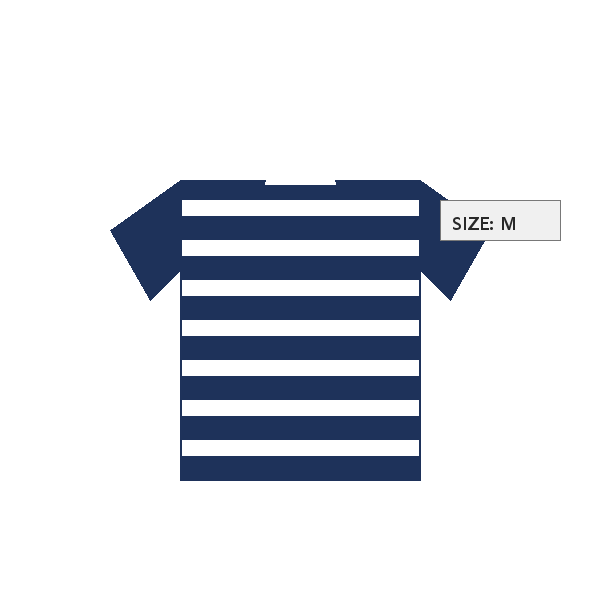

In [1]:
from vlm_utils import ask, ask_json, show

PRODUCT = "data/product.png"
show(PRODUCT)

## 상품 이미지 분석
프롬프트에 **쇼핑몰 카테고리 체계**를 함께 제시하면 분류 정확도가 올라갑니다.

In [2]:
category = ask(
    PRODUCT,
    "이 상품 이미지를 분석해서 아래 카테고리 중 하나로만 답하고, "
    "이유를 한 문장으로 덧붙여줘.\n"
    "카테고리: [의류, 신발, 가방, 액세서리, 가전, 기타]",
)
print(category)

의류  
이 이미지는 티셔츠를 표현한 것으로, 의류 카테고리에 해당합니다.


## 객체 인식 (Object Recognition)

In [3]:
objects = ask(
    PRODUCT,
    "이미지에 보이는 모든 객체를 나열하고, 각 객체의 대략적인 위치"
    "(왼쪽 위/가운데/오른쪽 아래 등)를 함께 알려줘.",
)
print(objects)

1. **T-셔츠 (블루/화이트 스트라이프 패턴)**  
   - **위치**: 가운데  
   - 설명: 전체 이미지 중앙에 위치한 주요 객체로, 파란색과 흰색의 수평 줄무늬가 특징적입니다.  

2. **SIZE: M 라벨**  
   - **위치**: 오른쪽 위  
   - 설명: T-셔츠의 우측 상단 부분에 붙어 있는 작은 텍스트 박스로, "SIZE: M"이라는 글자가 표시되어 있습니다.


## 속성 추출 (Attribute Extraction)
추출할 속성 목록을 미리 정의해주고, 이미지에 없는 속성은
**"unknown"으로 표기**하도록 지시해 근거 없는 추측을 막습니다.
(이 상품 이미지에는 "넥라인"이 명확히 보이지 않으므로 unknown이 나오는지 확인해보세요.)

In [4]:
attributes = ask_json(
    PRODUCT,
    '''
다음 속성만 추출해서 JSON으로만 답해: color, material, pattern, neckline, sleeve_length.
해당 속성이 이미지에서 명확히 확인되지 않으면 값으로 "unknown"을 넣어.
''',
)
print(attributes)

{'color': 'navy', 'material': 'unknown', 'pattern': 'stripes', 'neckline': 'crew neck', 'sleeve_length': 'short'}


## JSON 출력으로 파이프라인 통합
카테고리 + 객체 + 속성을 **하나의 스키마**로 합쳐 한 번에 뽑아봅니다.
이렇게 나온 JSON은 DB 적재·검색 인덱싱·추천 시스템 입력으로 바로 활용할 수 있습니다.

In [5]:
combined_schema = '''
아래 JSON 스키마로만 답해. 다른 텍스트는 출력하지 마.
{
  "category": "string",
  "objects": ["string"],
  "attributes": {
    "color": "string",
    "material": "string",
    "pattern": "string"
  }
}
'''
combined = ask_json(PRODUCT, combined_schema)
print(combined)
assert "category" in combined and "attributes" in combined

{'category': 'shirt', 'objects': ['t-shirt'], 'attributes': {'color': 'navy', 'material': 'cotton', 'pattern': 'striped'}}
